<a href="https://colab.research.google.com/github/pedrodamiaoluz/sentiment-analysis-imdb-RNNs/blob/main/Q5_da_LISTA_recurrent_network_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Importando as Bibliotecas

In [27]:
import numpy as np
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

## 1. Configurações e Hiperparâmetros

In [28]:
max_features = 10000  # limite do vocabulário do dataset
maxlen = 200          # timestamps
batch_size = 32
epochs = 10

## 2. Carregamento e Preparação do Dataset IMDB

In [30]:
(x_train, y_train), (x_test, y_test) = imdb.load_data(
    num_words=max_features
)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


## 3. Obtendo o caminho do dataset do IMDB

In [31]:
path = tf.keras.utils.get_file('imdb.npz', origin='https://storage.googleapis.com/tensorflow/tf-keras-datasets/imdb.npz')
with np.load(path, allow_pickle=True) as data:
    x_train_raw = data['x_train']
    y_train_raw = data['y_train']


dataset = pd.DataFrame({
    'Texto_Codificado': list(x_train_raw),
    'Sentimento': y_train_raw
})

print(dataset)

                                        Texto_Codificado  Sentimento
0      [23022, 309, 6, 3, 1069, 209, 9, 2175, 30, 1, ...           1
1      [23777, 39, 81226, 14, 739, 20387, 3428, 44, 7...           1
2      [527, 117, 113, 31, 16974, 1962, 3861, 115, 90...           1
3      [11, 6, 711, 1, 88, 2181, 19, 12518, 1, 3225, ...           1
4      [11, 6, 21, 1, 798, 3771, 3225, 19, 9, 13, 73,...           1
...                                                  ...         ...
24995  [946, 1, 127, 4, 1, 17, 10, 418, 9, 13, 96, 17...           0
24996  [11, 6, 1, 240, 4, 17, 12, 58, 4259, 1497, 10,...           0
24997  [10, 216, 77424, 233, 311, 30, 1, 21144, 19, 1...           0
24998  [46, 105, 12, 22, 1258, 53, 15, 3, 6564, 468, ...           0
24999  [11, 6, 28, 4, 1, 7051, 105, 204, 123, 107, 9,...           0

[25000 rows x 2 columns]


##  4. Padronização das sequências

In [32]:
print("Padronizando as sequências de texto...")
x_train = pad_sequences(x_train, maxlen=maxlen)
x_test = pad_sequences(x_test, maxlen=maxlen)

print(f"Formato dos dados de treino após padronização: {x_train.shape}")
print(f"Formato dos dados de teste após padronização: {x_test.shape}")

Padronizando as sequências de texto...
Formato dos dados de treino após padronização: (25000, 200)
Formato dos dados de teste após padronização: (25000, 200)


## 5. Construção da Rede Neural (Modelo LSTM)

In [33]:
print("Construindo o modelo...")

modelo = Sequential()
modelo.add(Embedding(input_dim=max_features, output_dim=128, input_length=maxlen))

modelo.add(LSTM(units = 128, return_sequences = True))
modelo.add(Dropout(0.2))

modelo.add(LSTM(units = 128, return_sequences = True))
modelo.add(Dropout(0.2))

modelo.add(LSTM(units = 64, return_sequences = False))
modelo.add(Dropout(0.2))


modelo.add(Dense(units = 1, activation='sigmoid'))

Construindo o modelo...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


## 6. Compilação do Modelo

In [34]:

modelo.compile(optimizer = 'adam', loss = 'binary_crossentropy', metrics=['accuracy'])

modelo.build(input_shape=(None, maxlen))
modelo.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_6 (LSTM)                   │ (None, 200, 128)       │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 200, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 200, 128)       │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 200, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_8 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,592,641 (6.08 MB)

 Trainable params: 1,592,641 (6.08 MB)

 Non-trainable params: 0 (0.00 B)

## 7. Iniciando o treinamento do modelo

In [35]:
print("\nIniciando o treinamento do modelo...")
historico = modelo.fit(
    x_train, y_train,
    batch_size=batch_size,
    epochs=epochs,
    validation_data=(x_test, y_test)
)


Iniciando o treinamento do modelo...
Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 33s 36ms/step - accuracy: 0.6640 - loss: 0.5861 - val_accuracy: 0.7780 - val_loss: 0.5087
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 28s 36ms/step - accuracy: 0.8073 - loss: 0.4258 - val_accuracy: 0.8456 - val_loss: 0.3729
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 28s 36ms/step - accuracy: 0.8890 - loss: 0.2829 - val_accuracy: 0.8642 - val_loss: 0.3160
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 28s 36ms/step - accuracy: 0.9191 - loss: 0.2184 - val_accuracy: 0.8687 - val_loss: 0.3329
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 28s 36ms/step - accuracy: 0.9376 - loss: 0.1769 - val_accuracy: 0.8608 - val_loss: 0.3908
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 28s 35ms/step - accuracy: 0.9505 - loss: 0.1436 - val_accuracy: 0.8639 - val_loss: 0.3846
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 28s 35ms/step - accuracy: 0.9660 - loss: 0.1084 - val_accuracy: 0.8638 - val_loss: 0.4111
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 28s 35ms/ste

## 8. Visualização das Predições vs Valor Real

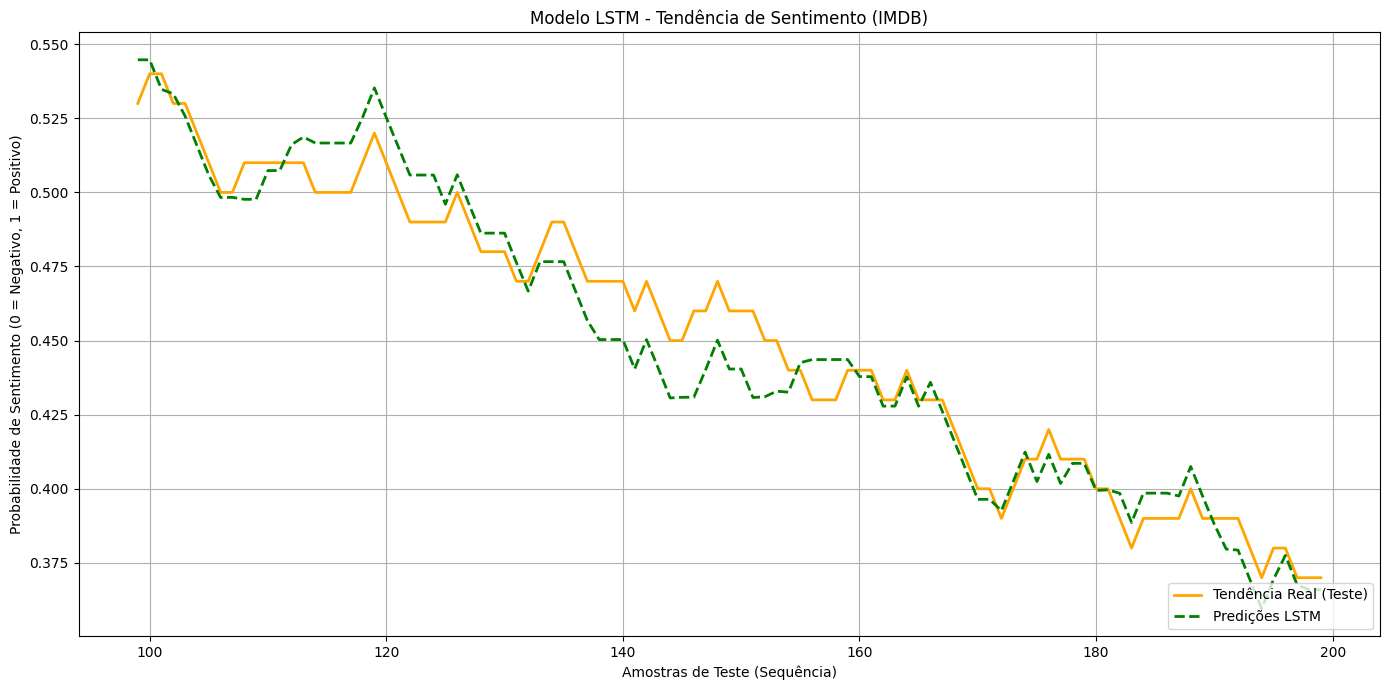

In [39]:
probabilidades_preditas = y_pred_prob.flatten()
janela_suavizacao = 100

n_amostras = maxlen

real_suavizado = pd.Series(y_true[:n_amostras]).rolling(window=janela_suavizacao).mean().values
prob_suavizada = pd.Series(probabilidades_preditas[:n_amostras]).rolling(window=janela_suavizacao).mean().values

plt.figure(figsize=(14, 7))
plt.plot(real_suavizado, color='orange', label='Tendência Real (Teste)', linewidth=2)
plt.plot(prob_suavizada, color='green', label='Predições LSTM', linestyle='--', linewidth=2)

plt.title('Modelo LSTM - Tendência de Sentimento (IMDB)')
plt.xlabel('Amostras de Teste (Sequência)')
plt.ylabel('Probabilidade de Sentimento (0 = Negativo, 1 = Positivo)')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()

## 7. Avaliação do modelo

In [37]:
x_test_fixed = pad_sequences(x_test, maxlen=maxlen)

y_pred_prob = modelo.predict(x_test_fixed)

y_pred = (y_pred_prob > 0.5).astype(int).flatten()

y_true = y_test

class_names = ['Negativo', 'Positivo']

relatorio = classification_report(y_true, y_pred, target_names=class_names)

print("Relatório de Classificação:\n")
print(relatorio)

782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step
Relatório de Classificação:

              precision    recall  f1-score   support

    Negativo       0.86      0.87      0.86     12500
    Positivo       0.87      0.85      0.86     12500

    accuracy                           0.86     25000
   macro avg       0.86      0.86      0.86     25000
weighted avg       0.86      0.86      0.86     25000

